# 00 — Project setup and experiment plan
**Goal:** prepare the folders and save the rules for our picture-learning experiment.

Our **classifier** is the picture learner. The **annotator** answers questions. The **controller** chooses a question or a short rest.

Run the cells from top to bottom. The first two notebooks only need NumPy, pandas, matplotlib, and Jupyter. PyTorch is needed later for the picture learner. If imports fail, run `%pip install -r ../requirements.txt` in a new cell, then restart the kernel. No classifier is trained in this notebook.

## 1. Load the tools and find our project
`Path` handles folders. The seed makes our random choices repeatable.

In [2]:
from pathlib import Path
import json
import platform
import importlib.metadata as metadata
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project = Path.cwd()
if project.name == 'notebooks':
    project = project.parent
assert (project / 'ProjectBrief.md').exists(), 'Open this notebook from the project folder.'
seed = 42
np.random.seed(seed)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False, 'axes.spines.right': False})
print('Project:', project)

Project: /Users/shaikha/MLProjects/advanced_ml


## 2. Create folders
Running this again keeps existing files.

In [3]:
folders = ['data/cifar10h', 'data/processed', 'data/splits', 'data/features', 'configs',
           'src/sim', 'src/control', 'src/learn', 'src/eval', 'tests',
           'outputs/setup', 'outputs/data_audit', 'outputs/sim_validation']
for folder in folders:
    (project / folder).mkdir(parents=True, exist_ok=True)
display(pd.DataFrame({'folder': folders}))

,folder
0,data/cifar10h
1,data/processed
2,data/splits
3,data/features
4,configs
5,src/sim
6,src/control
7,src/learn
8,src/eval
9,tests


## 3. Check the environment
These two notebooks work on a CPU. Missing PyTorch is fine for now; install it before Notebook 02.

In [5]:
versions = {name: metadata.version(name) for name in ['numpy', 'pandas', 'matplotlib', 'nbformat', 'nbclient', 'ipykernel', 'torch', 'torchvision']}
environment = {'python': platform.python_version(), 'packages': versions, 'device': 'CPU'}
if importlib.util.find_spec('torch'):
    import torch
    torch.manual_seed(seed)
    environment['torch'] = torch.__version__
    if torch.cuda.is_available():
        environment['device'] = 'CUDA GPU'
    elif torch.backends.mps.is_available():
        environment['device'] = 'Apple GPU (MPS)'
print('Compute device:', environment['device'])
display(pd.Series(versions, name='installed version').to_frame())
(project / 'outputs/setup/environment.json').write_text(json.dumps(environment, indent=2))

Compute device: Apple GPU (MPS)


,installed version
numpy,2.5.5
pandas,3.1.1
matplotlib,3.11.2
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.4.0
torch,2.15.0
torchvision,0.29.2


300

## 4. Save the starting settings
**Beta** controls how much tiredness hurts answer quality. **Lambda** controls the time charge in our score. Both will be varied later, rather than choosing a winner now.

Image allocation below is a **new implementation choice**: 4,000 learning-pool images, 2,000 difficulty-predictor images, 2,000 validation images, and 2,000 final-test images. Split sizes are per dataset, not per person.

In [6]:
settings = {
    'seed': seed, 'session_steps': 150, 'extra_session_steps': 300,
    'seed_images': [50, 200], 'retrain_every_answers': 10, 'uncertain_pool_size': 500,
    'budgets_seconds': [300, 600, 1200, 2400],
    'fatigue_levels': [0, 1, 2, 3, 4], 'beta_grid': [0, 0.5, 1, 2, 3],
    'lambda_initial': 1.0, 'recovery_probability': 0.35,
    'relative_time': {'skip': 0.1, 'verify': 0.35, 'two_choice': 0.6, 'full': 1.0},
    'fatigue_increase_probability': {'verify': 0.06, 'two_choice': 0.12, 'full': 0.25},
    'annotator_fractions': {'train': 0.6, 'validation': 0.2, 'test': 0.2},
    'image_counts_per_class': {'pool': 400, 'difficulty_train': 200, 'validation': 200, 'final_test': 200},
    'reaction_time_limits_ms': [200, 30000],
    'minimum_stage1_episodes_per_cell': 500, 'minimum_stage2_seeds': 10,
    'split_origin': 'New seed-42 split; original test IDs were not supplied'
}
settings_path = project / 'configs/project_settings.json'
if settings_path.exists():
    assert json.loads(settings_path.read_text()) == settings, 'Saved settings differ. Review changes before replacing them.'
else:
    settings_path.write_text(json.dumps(settings, indent=2))
display(pd.Series(settings, name='setting').to_frame())

,setting
seed,42
session_steps,150
extra_session_steps,300
seed_images,"[50, 200]"
retrain_every_answers,10
uncertain_pool_size,500
budgets_seconds,"[300, 600, 1200, 2400]"
fatigue_levels,"[0, 1, 2, 3, 4]"
beta_grid,"[0, 0.5, 1, 2, 3]"
lambda_initial,1.0


## 5. Picture the available actions
Relative time means a fraction of a full-label question's time, **not seconds**. A full question is the reference value 1. Real response times are added in the simulator.

,action,example,relative_time
0,Skip / rest,Let the picture pass,0.10
1,Verify,Is this a cat?,0.35
2,Two-choice,"Cat, dog, or neither?",0.60
3,Full label,Which of 10 classes?,1.00


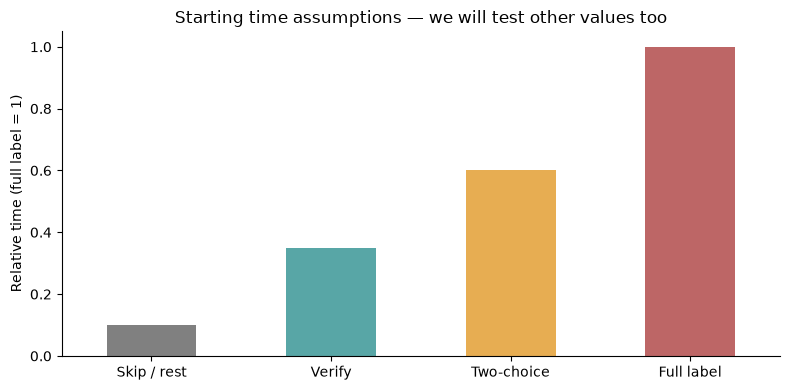

In [7]:
actions = pd.DataFrame({
    'action': ['Skip / rest', 'Verify', 'Two-choice', 'Full label'],
    'example': ['Let the picture pass', 'Is this a cat?', 'Cat, dog, or neither?', 'Which of 10 classes?'],
    'relative_time': list(settings['relative_time'].values())
})
display(actions)
actions.plot.bar(x='action', y='relative_time', legend=False, color=['gray', '#58a6a6', '#e7ad52', '#bd6666'])
plt.ylabel('Relative time (full label = 1)')
plt.xlabel('')
plt.title('Starting time assumptions — we will test other values too')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(project / 'outputs/setup/action_time_assumptions.png', dpi=150)
plt.show()

## 6. What counts as success?
We choose the main controller on **validation people**, never on final-test results.

| Rule | Plain meaning |
|---|---|
| Main controller | Highest mean Stage-1 validation net reward across the fatigue grid, excluding M-None |
| Close results | Within one standard error, prefer QMDP, then belief-grid POMDP, then DQN |
| No-fatigue case | Always report it; the real records do not establish average fatigue |
| Fair comparisons | Fixed types, random, published-style rules, greedy controller, and oracle |
| Hidden-state rule | Ordinary controllers cannot see real fatigue, private person parameters, or true labels |
| Final exam | Evaluate the reserved image test set only after all choices are frozen |
| Repetition | Save settings and seeds; report paired differences with 95% confidence intervals |

**Net reward** = information gained − lambda × time. **Greedy** means choosing only
for the immediate reward. **Oracle** is a reference controller allowed to see true fatigue. A confidence interval shows uncertainty in an estimated improvement.

## 7. Where we go next
**Data → checked simulator → controllers → fast comparisons → full learning → final figures.**

Next open `01_human_answer_data_exploration_and_splits.ipynb`. Saved here: project folders, `configs/project_settings.json`, environment details, and the action-time plot. The simulator, classifiers, and controllers are later work.